# Stats 161 Midterm Project

## Data import

We select **24 consecutive weeks of Polymarket data, from January 1 to June 17, 2026**, to study wallet trading behavior. All dates and timestamps use UTC.


### 1. Setup


In [5]:
import pandas as pd
import requests

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from io import BytesIO


### 2. Dates and access settings


In [6]:
import os
from getpass import getpass

start_date = "2026-01-01"
end_date = "2026-06-17"
dates = pd.date_range(start_date, end_date, freq="D", tz="UTC")

base_url = "https://d1yyqbluk0oz0t.cloudfront.net"
course_password = os.environ.get("POLYMARKET_PASSWORD") or getpass("Course password: ")


### 3. Wallet trades

We combine the 168 daily trade files into `wallet_trades`, keeping all wallets and all eight original variables. Each row is a recorded fill; one order may produce multiple fills.

| Variable | Description |
|---|---|
| `wallet` | Pseudonymous wallet ID, consistent across daily files. |
| `market` | Market slug; links to `markets.slug`. |
| `time` | Fill timestamp in UTC. |
| `side` | BUY or SELL for the recorded wallet. |
| `outcome` | Traded outcome, such as Yes, No, Up, Down, or a team name. |
| `price` | Execution price per share. |
| `size` | Number of shares traded. |
| `dollars` | Recorded dollar value of the fill. |


In [7]:
session = requests.Session()
session.auth = ("polymarketdatabase", course_password)
daily_trades = []

for day in dates:
    date_string = day.strftime("%Y-%m-%d")
    url = f"{base_url}/wallet_trades/trades-{date_string}.parquet"

    response = session.get(url, timeout=120)
    response.raise_for_status()
    day_trades = pd.read_parquet(BytesIO(response.content), dtype_backend="pyarrow")
    day_trades["time"] = pd.to_datetime(day_trades["time"], utc=True)

    # Check the file date.
    assert len(day_trades) > 0, f"Empty file: {date_string}"
    assert day_trades["time"].min().date() == day.date(), f"Unexpected date: {date_string}"
    assert day_trades["time"].max().date() == day.date(), f"Unexpected date: {date_string}"

    daily_trades.append(day_trades)
    if len(daily_trades) % 28 == 0:
        print(f"Loaded {len(daily_trades)} of {len(dates)} daily files.")

wallet_trades = pd.concat(daily_trades, ignore_index=True)
session.close()
del daily_trades, day_trades, response

print(f"Wallet trades imported: {len(wallet_trades):,} rows.")


Loaded 28 of 168 daily files.
Loaded 56 of 168 daily files.
Loaded 84 of 168 daily files.
Loaded 112 of 168 daily files.
Loaded 140 of 168 daily files.
Loaded 168 of 168 daily files.
Wallet trades imported: 56,738,552 rows.


### 4. Related market data

We import market, event, and settlement records for the markets in `wallet_trades`. All original columns are retained; key variables are listed below.

| DataFrame | Content | Key variables |
|---|---|---|
| `markets` | Market questions, outcome labels, and parent events. | `slug`, `title`, `event_slug`, `condition_id`, `outcomes`, `token_ids`, `start_date`, `end_date` |
| `events` | Event titles, descriptions, and scheduled dates. | `slug`, `title`, `description`, `start_date`, `end_date` |
| `resolutions` | Available settlement records. | `market_slug`, `resolved_yes`, `price_at_close`, `resolved_at` |

**Links:** `wallet_trades.market` → `markets.slug`; `markets.event_slug` → `events.slug`; `resolutions.market_slug` → `markets.slug`.

Market prices and volumes in the metadata reflect the current stored snapshot. Interpret resolution labels using the market's actual outcome labels.


In [8]:
database_url = URL.create(
    "postgresql+psycopg2",
    username="polymarketdatabase.merbqatlxbrcvtbnuaqe",
    password=course_password,
    host="aws-0-us-west-2.pooler.supabase.com",
    port=6543,
    database="postgres",
)

engine = create_engine(
    database_url,
    connect_args={"sslmode": "require", "connect_timeout": 20},
    execution_options={"postgresql_readonly": True},
)

market_slugs = wallet_trades["market"].dropna().unique().tolist()

with engine.connect() as connection:
    markets = pd.read_sql_query(
        text("SELECT * FROM public.markets WHERE slug = ANY(:slugs)"),
        connection,
        params={"slugs": market_slugs},
    )
    resolutions = pd.read_sql_query(
        text("SELECT * FROM public.resolutions WHERE market_slug = ANY(:slugs)"),
        connection,
        params={"slugs": market_slugs},
    )


In [9]:
event_slugs = markets["event_slug"].dropna().unique().tolist()

with engine.connect() as connection:
    events = pd.read_sql_query(
        text("SELECT * FROM public.events WHERE slug = ANY(:slugs)"),
        connection,
        params={"slugs": event_slugs},
    )

engine.dispose()


### 5. Import check

Confirm the row and column counts, and report traded markets without matching catalog metadata.


In [10]:
for name, data in [("wallet_trades", wallet_trades), ("markets", markets),
                   ("events", events), ("resolutions", resolutions)]:
    print(f"{name}: {len(data):,} rows, {len(data.columns)} columns")

missing_market_slugs = set(market_slugs) - set(markets["slug"])
print(f"Traded market slugs without catalog metadata: {len(missing_market_slugs):,}")
print(f"Study period: {start_date} through {end_date} (UTC)")


wallet_trades: 56,738,552 rows, 8 columns
markets: 146,182 rows, 25 columns
events: 59,566 rows, 13 columns
resolutions: 31,893 rows, 6 columns
Traded market slugs without catalog metadata: 66
Study period: 2026-01-01 through 2026-06-17 (UTC)


## Data Cleaning

### 1. Check data quality

Check missing values, trade fields, recorded amounts (tolerance: $0.01), repeated rows, and market links. Counts can overlap.


In [11]:
missing_values = wallet_trades.isna().any(axis=1)
invalid_side = ~wallet_trades["side"].isin(["BUY", "SELL"])
invalid_price = ~wallet_trades["price"].between(0, 1)
negative_size = wallet_trades["size"] < 0
negative_dollars = wallet_trades["dollars"] < 0
amount_mismatch = (
    wallet_trades["dollars"] - wallet_trades["price"] * wallet_trades["size"]
).abs() > 0.01
repeated_rows = wallet_trades.duplicated()
missing_metadata = ~wallet_trades["market"].isin(markets["slug"])

quality_check = pd.Series({
    "Missing values in any trade column": missing_values.sum(),
    "Side outside BUY / SELL": invalid_side.sum(),
    "Price outside [0, 1]": invalid_price.sum(),
    "Negative shares": negative_size.sum(),
    "Negative dollar value": negative_dollars.sum(),
    "Dollar difference above $0.01": amount_mismatch.sum(),
    "Repeated rows after the first": repeated_rows.sum(),
    "Trades without market metadata": missing_metadata.sum(),
}, name="Rows").to_frame()

quality_check


,Rows
Missing values in any trade column,0
Side outside BUY / SELL,0
"Price outside [0, 1]",0
Negative shares,0
Negative dollar value,0
Dollar difference above $0.01,0
Repeated rows after the first,1397127
Trades without market metadata,91462


### 2. Prepare the analysis data

Use `clean_trades` for the next analysis steps.

The checks found no missing or invalid trade values, so no rows need to be removed.

Repeated rows are kept because identical records cannot be confirmed as duplicates without a trade ID. Trades without market metadata are also kept. `has_market_metadata` indicates whether a trade's `market` matches `markets.slug`.

Large trades and low-activity wallets are retained.


In [12]:
clean_trades = wallet_trades.copy()
clean_trades["has_market_metadata"] = ~missing_metadata

print(f"Rows retained: {len(clean_trades):,}")
print(f"Rows removed: {len(wallet_trades) - len(clean_trades):,}")


Rows retained: 56,738,552
Rows removed: 0


## Wallet Features

**Question:** what trading styles appear in the recorded wallets, and how do the original groups' later BUY entries settle?

### 1. Three eight-week windows

Build one row per wallet and 56-day window. Fit profiles on window 1; keep its labels fixed when comparing subsequent purchases. Later-window profiles describe changes in observed behavior.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

windows = pd.DataFrame({
    "window": [1, 2, 3],
    "start": ["2026-01-01", "2026-02-26", "2026-04-23"],
    "end": ["2026-02-25", "2026-04-22", "2026-06-17"],
    "purpose": ["Build profiles", "First follow-up", "Second follow-up"],
})
windows

,window,start,end,purpose
0,1,2026-01-01,2026-02-25,Build profiles
1,2,2026-02-26,2026-04-22,First follow-up
2,3,2026-04-23,2026-06-17,Second follow-up


In [ ]:
feature_trades = clean_trades.copy()
for column in ["wallet", "market", "outcome"]:
    feature_trades[column] = feature_trades[column].astype("string[pyarrow]")
feature_trades["day"] = feature_trades["time"].dt.floor("D")
feature_trades["window"] = (
    (feature_trades["day"] - pd.Timestamp(start_date, tz="UTC")).dt.days // 56 + 1
)
feature_trades["buy_dollars"] = feature_trades["dollars"].where(feature_trades["side"].eq("BUY"), 0)
feature_trades["low_buy_dollars"] = feature_trades["dollars"].where(
    feature_trades["side"].eq("BUY") & feature_trades["price"].le(0.10), 0
)
group_keys = ["wallet", "window"]

In [19]:
import gc
del wallet_trades, clean_trades
gc.collect()

591

### 2. Activity and trade size

All recorded BUY and SELL fills contribute. Fill frequency is not order frequency; an order may have multiple fills. Dollar totals measure recorded turnover, not wallet wealth or profit.

In [15]:
wallet_features = feature_trades.groupby(group_keys).agg(
    n_fills=("size", "size"), active_days=("day", "nunique"),
    median_fill_dollars=("dollars", "median"), n_markets=("market", "nunique"),
    total_dollars=("dollars", "sum"),
)
wallet_features["fills_per_active_day"] = wallet_features["n_fills"] / wallet_features["active_days"]

### 3. Concentration and trading direction

The two-sided feature requires BUY and SELL in the **same outcome**. BUY Yes and SELL No alone do not count as two-sided trading here. `low_price_buy_share` uses all recorded BUY+SELL dollars as its denominator.

In [16]:
market_dollars = feature_trades.groupby(group_keys + ["market"])["dollars"].sum()
wallet_features["top_market_share"] = market_dollars.groupby(level=group_keys).max() / wallet_features["total_dollars"]
wallet_features["buy_dollar_share"] = feature_trades.groupby(group_keys)["buy_dollars"].sum() / wallet_features["total_dollars"]
wallet_features["low_price_buy_share"] = feature_trades.groupby(group_keys)["low_buy_dollars"].sum() / wallet_features["total_dollars"]

outcome_sides = feature_trades.groupby(group_keys + ["market", "outcome"])["side"].nunique()
both_sides = outcome_sides.eq(2).groupby(level=group_keys + ["market"]).any()
wallet_features["buy_sell_market_share"] = both_sides.groupby(level=group_keys).sum() / wallet_features["n_markets"]

In [17]:
buy_totals = feature_trades.loc[feature_trades["side"].eq("BUY")].groupby(group_keys).agg(
    buy_dollars=("dollars", "sum"), buy_shares=("size", "sum"),
)
wallet_features["avg_buy_price"] = buy_totals["buy_dollars"] / buy_totals["buy_shares"]

cluster_features = [
    "fills_per_active_day", "median_fill_dollars", "n_markets", "top_market_share",
    "buy_dollar_share", "buy_sell_market_share", "low_price_buy_share",
]
wallet_features = wallet_features.reset_index()[
    group_keys + cluster_features + ["n_fills", "active_days", "total_dollars", "avg_buy_price"]
]
print(f"Wallet-window rows: {len(wallet_features):,}")
print(f"Distinct recorded wallets: {wallet_features['wallet'].nunique():,}")
wallet_features.head()

Wallet-window rows: 1,224,035
Distinct recorded wallets: 892,982


,wallet,window,fills_per_active_day,median_fill_dollars,n_markets,top_market_share,buy_dollar_share,buy_sell_market_share,low_price_buy_share,n_fills,active_days,total_dollars,avg_buy_price
0,0x000025e0e96474e2485e259558e53f2dd4a54626,3,12.0,42.349999,35,0.099013,0.580817,0.371429,0.0,48,4,2188.836554,0.50222
1,0x000028713780b8882e3f11559f9c173802b3d716,3,34.615385,18.899529,209,0.052644,0.521184,0.698565,0.022298,450,13,11413.766335,0.202159
2,0x00003658b8a1a559b2e1753b42a87befdf08af13,1,1.0,3.190652,1,1.0,0.501456,1.000000,0.0,2,2,6.381304,0.992
3,0x0000381a4e54c779318b9005f6c637cafb631e62,2,2.387097,10.4725,32,0.123777,0.602199,0.625000,0.048606,74,31,2680.22227,0.221525
4,0x0000381a4e54c779318b9005f6c637cafb631e62,3,2.424242,67.7515,42,0.093086,0.709177,0.428571,0.019239,80,33,4157.74058,0.466749


### 5. Additional features: timing and time before settlement

The original inputs mostly measure **how much and how broadly** a wallet trades. Two feature families add **how and when** it trades:

| Feature | Definition (one wallet, one eight-week window) | Why |
|---|---|---|
| `active_hours` | distinct UTC hours of day with a fill (1–24) | programs trade around the clock; people sleep |
| `hour_entropy` | entropy of fills across the 24 hours, scaled to 0–1 | evenly spread activity suggests automation |
| `median_gap_seconds` | median time between consecutive distinct fill timestamps | very short gaps suggest automation |
| `multi_market_second_share` | share of active seconds with fills in ≥ 2 different markets | simultaneous trading across markets is hard by hand |
| `median_hours_to_close` | median hours from a BUY to the market's end cutoff | early positioning vs last-minute betting |
| `last_day_buy_share` | BUY dollars in the final 24 hours / BUY dollars with a known cutoff | last-minute concentration |
| `late_longshot_share` | BUY dollars at price ≤ 0.20 in the final 24 hours / same denominator | cheap bets right before the end, the pattern insider studies look for |

The end cutoff is the earlier of the scheduled end and the resolution time (the same conservative choice as the settlement section). Buys at or after the cutoff are excluded. DuckDB computes these on disk-backed tables, so the 24-week data does not need another in-memory copy.

In [20]:
import duckdb

fe_db = duckdb.connect()
fe_db.execute("SET TimeZone = 'UTC'")
fe_db.execute("SET memory_limit = '4GB'")          # raise if your computer has more than 16 GB of RAM
fe_db.execute("SET temp_directory = 'duckdb_tmp'")
fe_db.execute("SET preserve_insertion_order = false")
fe_db.execute("SET threads = 2")

market_end = markets[["slug", "end_date"]].rename(columns={"slug": "market"})
market_end["end_date"] = pd.to_datetime(market_end["end_date"], utc=True, errors="coerce")
resolved = resolutions.set_index("market_slug")["resolved_at"]
market_end["resolved_at"] = pd.to_datetime(market_end["market"].map(resolved), utc=True, errors="coerce")
market_end["market_end"] = market_end[["end_date", "resolved_at"]].min(axis=1)
market_end = market_end.dropna(subset=["market_end"])[["market", "market_end"]]

fe_db.register("ft", feature_trades)
fe_db.register("market_end", market_end)

fe_db.execute('''CREATE OR REPLACE TABLE fe_hours AS
    WITH h AS (SELECT wallet, "window", hour(time) AS hr, count(*) AS n FROM ft GROUP BY ALL),
    t AS (SELECT *, sum(n) OVER (PARTITION BY wallet, "window") AS total FROM h)
    SELECT wallet, "window", count(*) AS active_hours,
           -sum(n / total * ln(n / total)) / ln(24) AS hour_entropy
    FROM t GROUP BY ALL''')

fe_db.execute('''CREATE OR REPLACE TABLE fe_seconds AS
    WITH s AS (
        SELECT wallet, "window", date_trunc('second', time) AS sec, count(DISTINCT market) AS markets
        FROM ft GROUP BY ALL
    )
    SELECT wallet, "window", avg((markets >= 2)::INT) AS multi_market_second_share FROM s GROUP BY ALL''')

# Gaps need a sort per wallet, the most memory-hungry step: use integer wallet ids and
# millisecond integers, and sort one eight-week window at a time.
fe_db.execute('''CREATE OR REPLACE TABLE wallet_ids AS
    SELECT wallet, row_number() OVER () AS wid FROM (SELECT DISTINCT wallet FROM ft)''')
fe_db.execute('CREATE OR REPLACE TABLE fe_gaps_id (wid BIGINT, "window" BIGINT, median_gap_seconds DOUBLE)')
for w in sorted(feature_trades["window"].unique()):
    fe_db.execute(f'''INSERT INTO fe_gaps_id
        WITH d AS (SELECT i.wid, epoch_ms(t.time) AS ms FROM ft t JOIN wallet_ids i USING (wallet)
                   WHERE t."window" = {int(w)}),
        g AS (SELECT wid, ms - lag(ms) OVER (PARTITION BY wid ORDER BY ms) AS gap FROM d)
        SELECT wid, {int(w)}, approx_quantile(gap, 0.5) / 1000.0 FROM g WHERE gap > 0 GROUP BY wid''')
fe_db.execute('''CREATE OR REPLACE TABLE fe_gaps AS
    SELECT i.wallet, g."window", g.median_gap_seconds FROM fe_gaps_id g JOIN wallet_ids i USING (wid)''')

fe_db.execute('''CREATE OR REPLACE TABLE fe_close AS
    WITH b AS (
        SELECT t.wallet, t."window", t.price, t.dollars,
               (epoch(e.market_end) - epoch(t.time)) / 3600 AS hours_to_close
        FROM ft t JOIN market_end e USING (market)
        WHERE t.side = 'BUY' AND t.time < e.market_end AND t.dollars > 0
    )
    SELECT wallet, "window",
           approx_quantile(hours_to_close, 0.5)                                     AS median_hours_to_close,
           coalesce(sum(dollars) FILTER (WHERE hours_to_close <= 24), 0) / sum(dollars) AS last_day_buy_share,
           coalesce(sum(dollars) FILTER (WHERE hours_to_close <= 24 AND price <= 0.20), 0) / sum(dollars)
                                                                                    AS late_longshot_share
    FROM b GROUP BY ALL''')

new_features_table = fe_db.execute('''
    SELECT h.wallet, h."window", h.active_hours, h.hour_entropy, s.multi_market_second_share,
           g.median_gap_seconds, c.median_hours_to_close, c.last_day_buy_share, c.late_longshot_share
    FROM fe_hours h
    JOIN fe_seconds s USING (wallet, "window")
    LEFT JOIN fe_gaps g USING (wallet, "window")
    LEFT JOIN fe_close c USING (wallet, "window")
''').df()
fe_db.unregister("ft")
fe_db.close()

new_features = [
    "active_hours", "hour_entropy", "median_gap_seconds", "multi_market_second_share",
    "median_hours_to_close", "last_day_buy_share", "late_longshot_share",
]
new_features_table["wallet"] = new_features_table["wallet"].astype(wallet_features["wallet"].dtype)
new_features_table["window"] = new_features_table["window"].astype(wallet_features["window"].dtype)
wallet_features = wallet_features.drop(columns=new_features, errors="ignore").merge(
    new_features_table, on=["wallet", "window"], how="left", validate="one_to_one"
)
wallet_features[new_features].describe(percentiles=[0.1, 0.5, 0.9]).T.round(3)

,count,mean,std,min,10%,50%,90%,max
active_hours,1224035.0,5.132,6.037,1.0,1.000,2.000,15.000,24.000
hour_entropy,1224035.0,0.317,0.299,-0.0,0.000,0.218,0.780,1.000
median_gap_seconds,956412.0,215615.094,526412.203,1.0,28.000,12709.000,671273.600,4796739.000
multi_market_second_share,1224035.0,0.005,0.052,0.0,0.000,0.000,0.000,1.000
median_hours_to_close,1123241.0,5657.864,7485.518,0.0,4.895,2675.986,22545.082,25012.092
last_day_buy_share,1123241.0,0.175,0.354,0.0,0.000,0.000,1.000,1.000
late_longshot_share,1123241.0,0.022,0.117,0.0,0.000,0.000,0.000,1.000


`median_gap_seconds` is missing for wallets with a single distinct fill time, and the settlement-timing features are missing when no BUY has a known end cutoff. For modelling, missing settlement-timing values take the window median.

### 6. Which features describe a wallet consistently?

A useful profile feature should take similar values for the same wallet in consecutive windows. For wallets eligible in both windows, the table reports the Spearman correlation of each feature between windows 1→2 and 2→3 (test–retest reliability). Low values mean the feature mostly reflects noise or short-term circumstances, which pushes wallets between styles.

In [21]:
eligible_rows = wallet_features[
    wallet_features["n_fills"].ge(10) & wallet_features["active_days"].ge(3) & wallet_features["total_dollars"].gt(0)
]
all_candidates = cluster_features + new_features
reliability = {}
for earlier, later in [(1, 2), (2, 3)]:
    pair = eligible_rows[eligible_rows["window"].eq(earlier)].merge(
        eligible_rows[eligible_rows["window"].eq(later)], on="wallet", suffixes=("_a", "_b")
    )
    reliability[f"{earlier}→{later} (n={len(pair):,})"] = {
        feature: pair[f"{feature}_a"].astype(float).corr(pair[f"{feature}_b"].astype(float), method="spearman")
        for feature in all_candidates
    }
reliability = pd.DataFrame(reliability)
reliability["mean"] = reliability.mean(axis=1)
reliability["source"] = np.where(reliability.index.isin(new_features), "new", "original")
reliability.sort_values("mean", ascending=False).round(3)

,"1→2 (n=14,557)","2→3 (n=37,371)",mean,source
median_fill_dollars,0.871,0.856,0.863,original
buy_sell_market_share,0.755,0.724,0.739,original
low_price_buy_share,0.699,0.727,0.713,original
hour_entropy,0.604,0.526,0.565,new
multi_market_second_share,0.652,0.409,0.531,new
active_hours,0.563,0.462,0.512,new
top_market_share,0.484,0.536,0.510,original
fills_per_active_day,0.548,0.276,0.412,original
buy_dollar_share,0.332,0.467,0.399,original
median_gap_seconds,0.332,0.379,0.355,new


### 7. Do the new features give clearer and more stable profiles?

Each feature set goes through the same pipeline as the main model: `log1p` for counts, sizes and durations, a scaler and five-component GMM fitted on window 1, then frozen. Two checks:

* **Separation:** silhouette score on 5,000 window-1 wallets (higher is clearer).
* **Stability:** ARI between the frozen window-1 model's labels for window 2 and a model refitted on window 2 (higher means the same styles reappear).

The "reliable" set keeps features with mean test–retest correlation ≥ 0.5 from the table above (or the six most reliable if fewer than four reach 0.5).

In [43]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

log_candidates = ["fills_per_active_day", "median_fill_dollars", "n_markets",
                  "median_gap_seconds", "median_hours_to_close", "active_hours"]

def prepare(frame, features):
    data = frame[features].astype(float).copy()
    for feature in features:
        if feature in log_candidates:
            data[feature] = np.log1p(data[feature].clip(lower=0))
        data[feature] = data[feature].fillna(data[feature].median())
    return data

def evaluate(features, k=5):
    w1 = eligible_rows[eligible_rows["window"].eq(1)]
    w2 = eligible_rows[eligible_rows["window"].eq(2)]
    scaler = StandardScaler().fit(prepare(w1, features))
    X1, X2 = scaler.transform(prepare(w1, features)), scaler.transform(prepare(w2, features))
    settings = dict(n_components=k, covariance_type="full", n_init=3, reg_covar=1e-4, max_iter=500, random_state=161)
    frozen = GaussianMixture(**settings).fit(X1)
    refit = GaussianMixture(**settings).fit(X2)
    sample = np.random.default_rng(161).choice(len(X1), size=min(5000, len(X1)), replace=False)
    return {
        "features": len(features),
        "silhouette_window1": silhouette_score(X1[sample], frozen.predict(X1[sample])),
        "ARI_frozen_vs_refit_window2": adjusted_rand_score(frozen.predict(X2), refit.predict(X2)),
    }

ranked = reliability["mean"].dropna().sort_values(ascending=False)
reliable = ranked.index[ranked.ge(0.5)].tolist()
if len(reliable) < 4:                       # too few clear winners: keep the six most reliable instead
    reliable = ranked.index[:6].tolist()
usable = set(ranked.index)                  # drops features that never vary (correlation undefined)
feature_sets = {
    "Original 7": cluster_features,
    "Original + timing/settlement": [f for f in cluster_features + new_features if f in usable],
    "Most reliable": reliable,
    "Original + timing": cluster_features + ["hour_entropy", "multi_market_second_share", "active_hours"],
}
comparison = pd.DataFrame({name: evaluate(features) for name, features in feature_sets.items()}).T
print("Reliable features:", ", ".join(reliable))
comparison.round(3)

Reliable features: median_fill_dollars, buy_sell_market_share, low_price_buy_share, hour_entropy, multi_market_second_share, active_hours, top_market_share


,features,silhouette_window1,ARI_frozen_vs_refit_window2
Original 7,7.0,0.087,0.364
Original + timing/settlement,14.0,0.124,0.238
Most reliable,7.0,0.042,0.504
Original + timing,10.0,0.100,0.437


**How to use this:** if a new feature set raises both separation and stability, refit the main style model with it (replace `cluster_features` and re-run the clustering section). If neither improves, the honest conclusion is that wallet behavior forms a continuum rather than sharply separated types, which is itself a finding worth reporting.

## Wallet Clustering

### 1. Analysis sample and inputs

| Predictor | Meaning within one eight-week window |
|---|---|
| `fills_per_active_day` | Fills per observed trading day |
| `median_fill_dollars` | Typical fill size |
| `n_markets` | Breadth of market participation |
| `top_market_share` | Largest market's share of recorded dollars |
| `buy_dollar_share` | BUY dollars / all recorded dollars |
| `buy_sell_market_share` | Share of markets with both sides for a common outcome |
| `low_price_buy_share` | BUY dollars at prices ≤0.10 / all recorded dollars |
| `hour_entropy` | How evenly fills spread across the 24 UTC hours (0–1) |
| `multi_market_second_share` | Share of active seconds with fills in ≥ 2 markets |
| `active_hours` | Distinct UTC hours of day with a fill (1–24) |

At least 10 fills, 3 active days, and positive turnover are required for a profile. Low-activity wallets remain in the source data. `avg_buy_price` is share-weighted and used to describe groups; outcomes and returns are not clustering inputs.

In [44]:
eligible = wallet_features["n_fills"].ge(10) & wallet_features["active_days"].ge(3) & wallet_features["total_dollars"].gt(0)
profile_data = wallet_features.loc[eligible].copy().reset_index(drop=True)

profile_coverage = wallet_features.groupby("window").agg(
    observed_wallets=("wallet", "size"), all_fills=("n_fills", "sum"),
)
profile_coverage["profiled_wallets"] = profile_data.groupby("window").size()
profile_coverage["wallet_coverage_pct"] = 100 * profile_coverage["profiled_wallets"] / profile_coverage["observed_wallets"]
profile_coverage["fill_coverage_pct"] = 100 * profile_data.groupby("window")["n_fills"].sum() / profile_coverage["all_fills"]
profile_coverage.round(2)

,observed_wallets,all_fills,profiled_wallets,wallet_coverage_pct,fill_coverage_pct
window,,,,,
1,221118,3750808,39259,17.75,82.69
2,346399,9088542,85742,24.75,88.94
3,656518,43899202,201725,30.73,94.51


### 2. Fit the selected descriptive model

Use the five-component GMM selected in the [independent validation](wallet_style_settlement_validation.ipynb). That study compared GMM components 1–5 and K-means clusters 2–5; training BIC and resampling supported this GMM within that range. Five was the search boundary, not a verified count of natural trader types.

The independent validation compared models on the original seven inputs (training resampling median ARI 0.989; silhouette 0.087; ARI 0.271 with K-means). Section 7 of Wallet Features then compared feature sets with the same GMM pipeline. Adding the three timing features raised window-1 silhouette from 0.087 to 0.100 and agreement between the frozen and refitted window-2 models from 0.364 to 0.437, so the final model uses these ten inputs. Groups still overlap: these are **observed behavior profiles**, not verified bot, novice, whale, or insider identities.

Log-transform frequency, typical fill value, market count, and active hours. Fit the scaler and GMM on window 1 only, then freeze both.

In [84]:
cluster_features = list(dict.fromkeys(cluster_features + ["hour_entropy", "multi_market_second_share", "active_hours"]))
log_features = ["fills_per_active_day", "median_fill_dollars", "n_markets", "active_hours"]

inputs = profile_data[cluster_features].astype(float).copy()
inputs[log_features] = np.log1p(inputs[log_features])
training_mask = profile_data["window"].eq(1)

scaler = StandardScaler().fit(inputs.loc[training_mask])
X_train = scaler.transform(inputs.loc[training_mask])
X_all = scaler.transform(inputs)
style_model = GaussianMixture(
    n_components=5, covariance_type="full", n_init=3,
    reg_covar=1e-4, max_iter=500, random_state=161,
).fit(X_train)

training_profiles = profile_data.loc[training_mask].copy()
training_profiles["component"] = style_model.predict(X_train)
component_order = training_profiles.groupby("component")["fills_per_active_day"].median().sort_values().index
component_labels = {int(component): f"Style {i + 1}" for i, component in enumerate(component_order)}
profile_data["style"] = pd.Series(style_model.predict(X_all)).map(component_labels).to_numpy()
training_profiles = profile_data.loc[training_mask].copy()

style_names = {
    "Style 1": "Small long-shot buyers",
    "Style 2": "Mid-size mixed-price traders",
    "Style 3": "Large near-certainty traders",
    "Style 4": "Rapid small-ticket traders",
    "Style 5": "Round-the-clock diversified traders",
}

### 3. Describe the training profiles

Names reflect the training medians and were assigned before examining later settlement outcomes. They describe relative behavior in January–February, not permanent traits. In particular, two-sided fills alone do not establish market making.

In [85]:
style_summary = training_profiles.groupby("style").agg(
    wallets=("wallet", "size"), recorded_dollars=("total_dollars", "sum"),
)
style_summary["description"] = style_summary.index.map(style_names)
style_summary["wallet_share_pct"] = 100 * style_summary["wallets"] / len(training_profiles)
style_summary["turnover_share_pct"] = 100 * style_summary["recorded_dollars"] / style_summary["recorded_dollars"].sum()
style_summary[["description", "wallets", "wallet_share_pct", "turnover_share_pct"]].round(2)

,description,wallets,wallet_share_pct,turnover_share_pct
style,,,,
Style 1,Small long-shot buyers,8120,20.68,6.0
Style 2,Mid-size mixed-price traders,12828,32.68,37.81
Style 3,Large near-certainty traders,9070,23.1,34.89
Style 4,Rapid small-ticket traders,2718,6.92,9.44
Style 5,Round-the-clock diversified traders,6523,16.62,11.85


In [86]:
description_features = cluster_features + ["active_days", "total_dollars", "avg_buy_price"]
style_medians = training_profiles.groupby("style")[description_features].median().astype(float)
style_medians.T.round(3)

style,Style 1,Style 2,Style 3,Style 4,Style 5
fills_per_active_day,2.143,2.400,2.667,5.593,6.923
median_fill_dollars,9.000,20.300,292.231,5.532,29.967
n_markets,8.000,9.000,10.000,11.000,43.000
top_market_share,0.308,0.263,0.168,0.332,0.085
buy_dollar_share,0.573,0.524,0.500,0.503,0.518
buy_sell_market_share,0.667,0.750,1.000,0.840,0.938
low_price_buy_share,0.134,0.000,0.000,0.021,0.000
hour_entropy,0.573,0.658,0.653,0.605,0.860
multi_market_second_share,0.000,0.000,0.000,0.059,0.000
active_hours,7.000,9.000,9.000,11.000,22.000


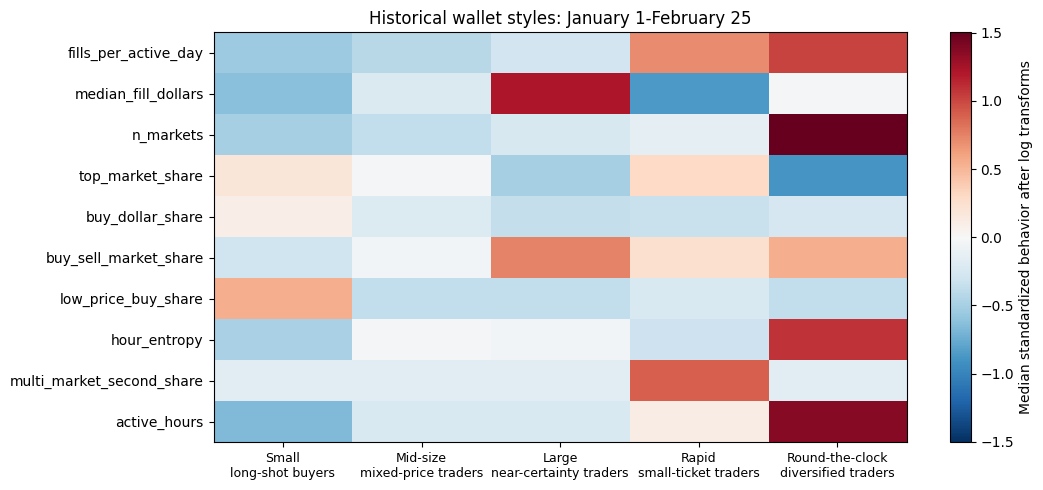

In [87]:
heatmap = pd.DataFrame(X_train, columns=cluster_features).assign(
    style=training_profiles["style"].to_numpy()
).groupby("style").median().T
fig, ax = plt.subplots(figsize=(11, 5))
limit = max(1, np.abs(heatmap.to_numpy()).max())
image = ax.imshow(heatmap, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(5), [style_names[style].replace(" ", "\n", 1) for style in heatmap.columns], fontsize=9)
ax.set_yticks(range(len(cluster_features)), cluster_features)
ax.set_title("Historical wallet styles: January 1-February 25")
fig.colorbar(image, ax=ax, label="Median standardized behavior after log transforms")
plt.tight_layout()
plt.show()

### 4. Follow the original cohort

Apply the frozen model to later eight-week behavior. A missing wallet means no recorded trades in that window, not a verified platform exit. Same-style percentages below use only wallets eligible for profiling again.

With the ten-input model, 56.2% of re-profiled wallets keep their style in window 2 and 41.9% in window 3 (52.2% and 40.8% with the original seven inputs). Agreement between frozen and refitted models remains moderate (ARI 0.437 in window 2), which limits an interpretation as stable identities. Population changes, behavior changes, and collection differences remain possible contributors.

In [88]:
baseline_profiles = training_profiles[["wallet", "style"]].rename(columns={"style": "baseline_style"})
wallet_profiles = profile_data[["wallet", "window", "style"]].copy()
cohort = pd.MultiIndex.from_product(
    [baseline_profiles["wallet"], [1, 2, 3]], names=["wallet", "window"]
).to_frame(index=False)
cohort = cohort.merge(baseline_profiles, on="wallet", how="left", validate="many_to_one")
cohort = cohort.merge(wallet_features[["wallet", "window", "n_fills"]], on=["wallet", "window"], how="left", validate="one_to_one")
cohort = cohort.merge(wallet_profiles, on=["wallet", "window"], how="left", validate="one_to_one")
cohort["status"] = "Insufficient activity"
cohort.loc[cohort["n_fills"].isna(), "status"] = "No recorded trades"
cohort.loc[cohort["style"].notna(), "status"] = "Profiled"
pd.crosstab(cohort["window"], cohort["status"])

status,Insufficient activity,No recorded trades,Profiled
window,,,
1,0,0,39259
2,9096,15606,14557
3,11578,17957,9724


In [89]:
followup_rows = []
for window in [2, 3]:
    group = cohort[cohort["window"].eq(window)]
    paired = group[group["style"].notna()]
    followup_rows.append({
        "window": window, "original_wallets": len(group),
        "wallets_with_records": int(group["n_fills"].notna().sum()),
        "profiled_again": len(paired),
        "same_style_pct_among_profiled": 100 * paired["style"].eq(paired["baseline_style"]).mean(),
    })
profile_followup = pd.DataFrame(followup_rows).set_index("window")
profile_followup.round(2)

,original_wallets,wallets_with_records,profiled_again,same_style_pct_among_profiled
window,,,,
2,39259,23653,14557,56.19
3,39259,21302,9724,41.88


## Settlement Comparison

### 1. Outcome sample and interpretation

Keep each original wallet's **window-1 label** when evaluating its later purchases. Use canonical `['Yes', 'No']` markets with a consistent terminal record before October 21, 2026. Other market labels remain in the profile study.

The recorded close time can fall back to a scheduled date; it is not a verified news timestamp. Exclude purchases at or after that time. Unmatched markets and wallets with no scored purchases are not assigned losses or zero returns.

Score **BUY entries hypothetically held to resolution**, ignoring actual SELLs: winning shares pay 1, losing shares pay 0. This benchmark describes entry outcomes before fees and rewards. It is not realized wallet PnL, full position accounting, or a measure of market-making profitability.

In [90]:
label_cutoff = pd.Timestamp("2026-10-21", tz="UTC")
settled = resolutions[["market_slug", "resolved_yes", "price_at_close", "resolved_at"]].merge(
    markets[["slug", "outcomes"]], left_on="market_slug", right_on="slug", how="inner", validate="one_to_one",
)
settled["resolved_at"] = pd.to_datetime(settled["resolved_at"], utc=True)
settled["price_at_close"] = pd.to_numeric(settled["price_at_close"])
canonical = settled["outcomes"].map(lambda labels: labels == ["Yes", "No"])
terminal = settled["price_at_close"].le(0.01) | settled["price_at_close"].ge(0.99)
consistent = settled["resolved_yes"].eq(settled["price_at_close"].gt(0.5))
settled = settled.loc[
    canonical & terminal & consistent
    & settled["resolved_at"].ge(pd.Timestamp(start_date, tz="UTC"))
    & settled["resolved_at"].lt(label_cutoff)
].copy()
settled["winning_outcome"] = np.where(settled["resolved_yes"], "Yes", "No")

buy_mask = (
    feature_trades["window"].isin([2, 3]) & feature_trades["side"].eq("BUY")
    & feature_trades["wallet"].isin(baseline_profiles["wallet"])
    & feature_trades["size"].gt(0) & feature_trades["dollars"].gt(0)
)
followup_buys = feature_trades.loc[
    buy_mask, ["wallet", "window", "market", "outcome", "time", "size", "dollars"]
].merge(baseline_profiles, on="wallet", how="inner", validate="many_to_one")
matched_buys = followup_buys.merge(
    settled[["market_slug", "resolved_at", "winning_outcome"]],
    left_on="market", right_on="market_slug", how="inner", validate="many_to_one",
)
scored_buys = matched_buys.loc[
    matched_buys["time"].lt(matched_buys["resolved_at"])
    & matched_buys["outcome"].isin(["Yes", "No"])
].copy()
scored_buys["won"] = scored_buys["outcome"].eq(scored_buys["winning_outcome"]).astype("int64")

In [91]:
settlement_coverage = followup_buys.groupby("window").agg(
    wallets_with_positive_buys=("wallet", "nunique"), buy_dollars=("dollars", "sum"),
)
settlement_coverage["scored_wallets"] = scored_buys.groupby("window")["wallet"].nunique()
settlement_coverage["scored_buy_dollars"] = scored_buys.groupby("window")["dollars"].sum()
settlement_coverage["scored_pct_of_original_wallets"] = 100 * settlement_coverage["scored_wallets"] / len(baseline_profiles)
settlement_coverage["scored_pct_of_cohort_buy_dollars"] = 100 * settlement_coverage["scored_buy_dollars"] / settlement_coverage["buy_dollars"]
settlement_coverage.round(2)

,wallets_with_positive_buys,buy_dollars,scored_wallets,scored_buy_dollars,scored_pct_of_original_wallets,scored_pct_of_cohort_buy_dollars
window,,,,,,
2,21270,157663813.36,13879,52856341.81,35.35,33.52
3,19597,225669487.62,14169,88923312.83,36.09,39.4


### 2. Hit rates and hypothetical returns

Aggregate once per wallet × market × outcome × window. This avoids counting split fills as independent wins. Buying both outcomes produces one entry for each side; hit rate alone does not measure skill.

Mean wallet hit rate and entry-price reference weight wallets equally. Pooled hypothetical ROI weights by BUY dollars; median wallet ROI describes a different, typical-wallet perspective.

In [92]:
entry_results = scored_buys.groupby(
    ["window", "baseline_style", "wallet", "market", "outcome"], as_index=False
).agg(
    buy_shares=("size", "sum"), buy_dollars=("dollars", "sum"), won=("won", "first"),
)
entry_results["avg_entry_price"] = entry_results["buy_dollars"] / entry_results["buy_shares"]
entry_results["hypothetical_profit"] = entry_results["buy_shares"] * entry_results["won"] - entry_results["buy_dollars"]

wallet_outcomes = entry_results.groupby(["window", "baseline_style", "wallet"], as_index=False).agg(
    settled_markets=("market", "nunique"), hit_rate=("won", "mean"),
    entry_price_reference=("avg_entry_price", "mean"),
    buy_dollars=("buy_dollars", "sum"), hypothetical_profit=("hypothetical_profit", "sum"),
)
wallet_outcomes["hypothetical_roi"] = wallet_outcomes["hypothetical_profit"] / wallet_outcomes["buy_dollars"]
performance = wallet_outcomes.groupby(["window", "baseline_style"]).agg(
    scored_wallets=("wallet", "size"), mean_wallet_hit_rate=("hit_rate", "mean"),
    mean_wallet_entry_price=("entry_price_reference", "mean"),
    median_wallet_roi=("hypothetical_roi", "median"),
    buy_dollars=("buy_dollars", "sum"), hypothetical_profit=("hypothetical_profit", "sum"),
)
performance["pooled_hypothetical_roi"] = performance["hypothetical_profit"] / performance["buy_dollars"]
baseline_counts = baseline_profiles["baseline_style"].value_counts()
performance["scored_pct_of_original_style"] = 100 * performance["scored_wallets"] / performance.index.get_level_values("baseline_style").map(baseline_counts)

outcome_summary = performance[[
    "scored_wallets", "scored_pct_of_original_style", "mean_wallet_entry_price", "mean_wallet_hit_rate",
    "median_wallet_roi", "pooled_hypothetical_roi",
]].copy()
for column in ["mean_wallet_entry_price", "mean_wallet_hit_rate", "median_wallet_roi", "pooled_hypothetical_roi"]:
    outcome_summary[column] = 100 * outcome_summary[column]
outcome_summary = outcome_summary.rename(columns={
    "scored_wallets": "Scored wallets", "scored_pct_of_original_style": "Original style covered (%)",
    "mean_wallet_entry_price": "Entry reference (%)", "mean_wallet_hit_rate": "Hit rate (%)",
    "median_wallet_roi": "Median wallet ROI (%)", "pooled_hypothetical_roi": "Pooled ROI (%)",
})
outcome_summary.round(2)

Scored wallets  Original style covered (%)  \
window baseline_style                                               
2      Style 1                   2617                       32.23   
       Style 2                   4548                       35.45   
       Style 3                   2534                       27.94   
       Style 4                    700                       25.75   
       Style 5                   3480                       53.35   
3      Style 1                   2979                       36.69   
       Style 2                   4701                       36.65   
       Style 3                   2855                       31.48   
       Style 4                    540                       19.87   
       Style 5                   3094                       47.43   

                       Entry reference (%)  Hit rate (%)  \
window baseline_style                                      
2      Style 1                       38.86         39.61   
       Style 2                       73.03         72.52   
       Style 3                       94.67         94.87   
       Style 4                       54.68         56.12   
       Style 5                       93.77         91.39   
3      Style 1                       49.18         48.82   
       Style 2                       70.65         69.13   
       Style 3                       92.67         92.69   
       Style 4                       52.57         52.66   
       Style 5                        91.5         93.36   

                       Median wallet ROI (%)  Pooled ROI (%)  
window baseline_style                                         
2      Style 1                        -16.49           -3.98  
       Style 2                          0.46            -1.8  
       Style 3                          0.29           -0.04  
       Style 4                         -0.85           -2.73  
       Style 5                          3.86           -5.33  
3      Style 1                         -0.51           10.67  
       Style 2                           0.3            6.94  
       Style 3                          0.32            0.64  
       Style 4                          0.73            0.83  
       Style 5                          3.84            -2.4

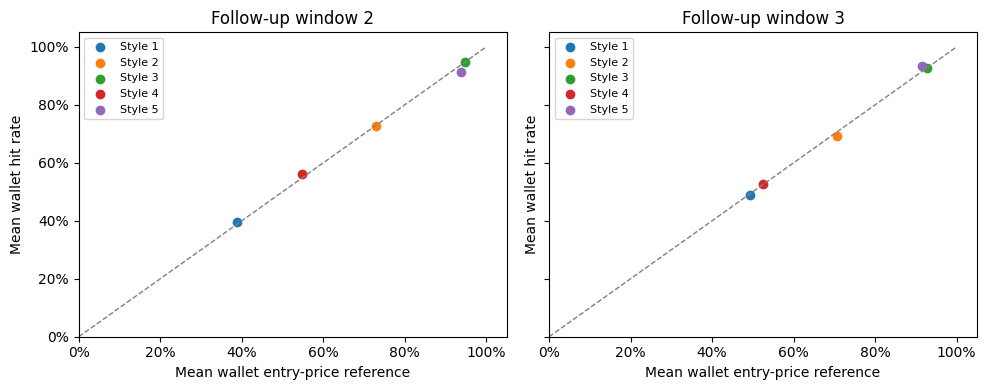

In [93]:
styles = list(style_names)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, window in zip(axes, [2, 3]):
    values = performance.loc[window].reindex(styles)
    ax.plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1)
    for style, row in values.iterrows():
        ax.scatter(row["mean_wallet_entry_price"], row["mean_wallet_hit_rate"], label=style)
    ax.set(xlim=(0, 1.05), ylim=(0, 1.05), xlabel="Mean wallet entry-price reference", ylabel="Mean wallet hit rate", title=f"Follow-up window {window}")
    ax.legend(loc="upper left", fontsize=8)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

### 3. Pooled results versus the typical wallet

High hit rates can follow from buying high-priced contracts. Entry prices are descriptive probability references, not a guarantee of calibration. Positive pooled returns can also coexist with a negative median wallet return; neither figure should stand in for the other.

The independent validation includes event-block intervals, price-band comparisons, and sensitivity samples. It found no group with a wholly positive pooled-return interval in both follow-ups. These observed point estimates do not establish a reliably profitable trader type.

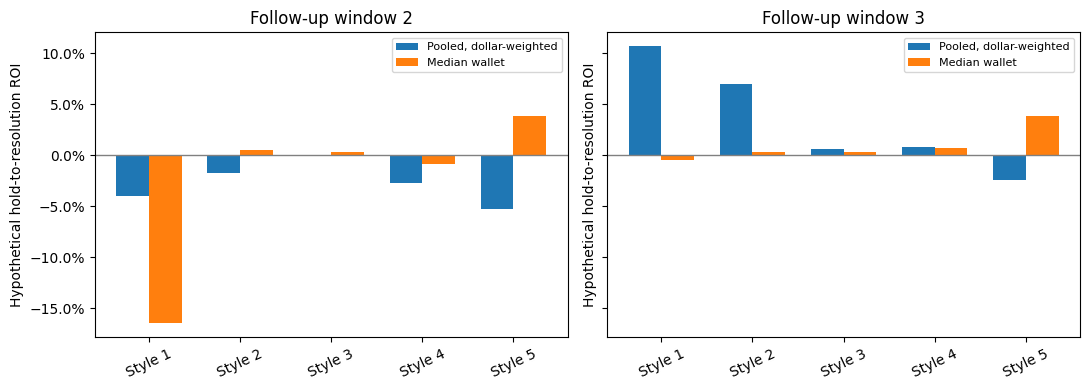

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
x = np.arange(len(styles))
for ax, window in zip(axes, [2, 3]):
    values = performance.loc[window].reindex(styles)
    ax.bar(x - 0.18, values["pooled_hypothetical_roi"], width=0.36, label="Pooled, dollar-weighted")
    ax.bar(x + 0.18, values["median_wallet_roi"], width=0.36, label="Median wallet")
    ax.axhline(0, color="grey", linewidth=1)
    ax.set_xticks(x, styles, rotation=25)
    ax.set_title(f"Follow-up window {window}")
    ax.set_ylabel("Hypothetical hold-to-resolution ROI")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 4. The last four weeks separately

The final four weeks contain 39.93 million fills, versus 3.97 million in the preceding four weeks. This observed coverage/composition change has an unresolved cause. Keep the original profiles and split only the later purchases below.

In [95]:
late_buys = scored_buys.loc[scored_buys["window"].eq(3)].copy()
late_buys["half"] = np.where(
    late_buys["time"].lt(pd.Timestamp("2026-05-21", tz="UTC")), "Apr 23-May 20", "May 21-Jun 17"
)
late_buys["hypothetical_profit"] = late_buys["size"] * late_buys["won"] - late_buys["dollars"]
late_comparison = late_buys.groupby(["baseline_style", "half"]).agg(
    buy_dollars=("dollars", "sum"), hypothetical_profit=("hypothetical_profit", "sum"),
)
late_comparison["pooled_roi_pct"] = 100 * late_comparison["hypothetical_profit"] / late_comparison["buy_dollars"]
late_comparison["pooled_roi_pct"].unstack("half").round(2)

half,Apr 23-May 20,May 21-Jun 17
baseline_style,,
Style 1,6.89,11.82
Style 2,-1.83,10.29
Style 3,0.79,0.43
Style 4,0.99,0.76
Style 5,-5.17,0.96


## Extension: Bots, Whales, Retail, and Skill Beyond Price

The five styles above are learned without labels. This section adds three simple checks that connect them to the project question (**retail, whales, bots, insiders, and who makes money**):

1. **Rule-based groups** from window-1 behavior: bots, whales, and retail. How do they overlap with the five styles?
2. **Who makes money?** Hypothetical hold-to-resolution ROI by group, with bootstrap intervals and a rank test.
3. **Skill beyond price.** A high hit rate can simply come from buying favorites. We compare each wallet's wins with the wins its entry prices imply. Wallets that win far more than prices imply are *candidates* for unusual information; we compare their count with what chance alone would produce.

All results remain observational and use the same hypothetical hold-to-resolution benchmark as above.

### 1. Rule-based groups in window 1

Rules are applied in order, using window-1 behavior only (so later outcomes cannot influence the labels):

| Group | Rule (one eight-week window) | Reason |
|---|---|---|
| Bot-like | ≥ 500 markets **or** ≥ 2,000 fills | Thresholds from the course insider demo; humans rarely trade this broadly or often |
| Whale | top 1% of recorded dollars among the remaining wallets | Size |
| Retail | everyone else | |

These are behavioral labels, not verified identities.

In [96]:
bot_markets, bot_fills, whale_top = 500, 2000, 0.01

groups = training_profiles[["wallet", "style", "n_markets", "n_fills", "total_dollars"]].copy()
is_bot = groups["n_markets"].ge(bot_markets) | groups["n_fills"].ge(bot_fills)
whale_cut = groups.loc[~is_bot, "total_dollars"].quantile(1 - whale_top)
groups["group"] = np.select(
    [is_bot, groups["total_dollars"].ge(whale_cut)], ["Bot-like", "Whale"], default="Retail"
)
group_order = ["Retail", "Whale", "Bot-like"]

group_summary = groups.groupby("group").agg(
    wallets=("wallet", "size"), recorded_dollars=("total_dollars", "sum"),
    median_fills=("n_fills", "median"), median_markets=("n_markets", "median"),
).reindex(group_order)
group_summary["wallet_share_pct"] = 100 * group_summary["wallets"] / len(groups)
group_summary["turnover_share_pct"] = 100 * group_summary["recorded_dollars"] / group_summary["recorded_dollars"].sum()
print(f"Whale cutoff: ${whale_cut:,.0f} recorded in window 1")
group_summary.round(2)

Whale cutoff: $57,053 recorded in window 1


,wallets,recorded_dollars,median_fills,median_markets,wallet_share_pct,turnover_share_pct
group,,,,,,
Retail,38784,179162838.67,23.0,11.0,98.79,63.43
Whale,392,86911271.45,45.0,16.0,1.0,30.77
Bot-like,83,16378695.76,4747.0,281.0,0.21,5.8


In [97]:
style_by_group = pd.crosstab(groups["style"].map(style_names), groups["group"], normalize="columns")
style_by_group = (100 * style_by_group).reindex(columns=group_order).round(1)
style_by_group.columns.name = "% of each group"
style_by_group

% of each group,Retail,Whale,Bot-like
style,,,
Large near-certainty traders,23.1,29.6,0.0
Mid-size mixed-price traders,32.6,50.8,0.0
Rapid small-ticket traders,6.7,8.7,100.0
Round-the-clock diversified traders,16.8,0.0,0.0
Small long-shot buyers,20.8,11.0,0.0


Reading the table: each column shows how a rule-based group spreads over the five learned styles. If whales or bot-like wallets concentrate in one or two styles, the unsupervised styles are picking up size and activity in a way that matches the simple rules.

### 2. Who makes money?

Wallets keep their window-1 group. ROI is the same hypothetical hold-to-resolution benchmark as above. Intervals resample **wallets** (1,000 bootstrap draws), so one large wallet cannot make a group look reliably profitable. The Kruskal–Wallis test asks whether typical wallet ROI differs across groups.

In [98]:
from scipy.stats import kruskal

group_of = groups.set_index("wallet")["group"]
outcomes = wallet_outcomes.assign(group=wallet_outcomes["wallet"].map(group_of))
rng = np.random.default_rng(161)

def pooled_roi_interval(frame, draws=1000):
    profit, dollars = frame["hypothetical_profit"].to_numpy(), frame["buy_dollars"].to_numpy()
    picks = rng.integers(0, len(frame), size=(draws, len(frame)))
    values = profit[picks].sum(axis=1) / dollars[picks].sum(axis=1)
    return np.percentile(values, [2.5, 97.5])

rows = []
for (window, group), frame in outcomes.groupby(["window", "group"]):
    low, high = pooled_roi_interval(frame)
    rows.append({
        "window": window, "group": group, "scored_wallets": len(frame),
        "hit_rate_pct": 100 * frame["hit_rate"].mean(),
        "entry_price_pct": 100 * frame["entry_price_reference"].mean(),
        "median_wallet_roi_pct": 100 * frame["hypothetical_roi"].median(),
        "pooled_roi_pct": 100 * frame["hypothetical_profit"].sum() / frame["buy_dollars"].sum(),
        "pooled_roi_low_pct": 100 * low, "pooled_roi_high_pct": 100 * high,
    })
money = pd.DataFrame(rows).set_index(["window", "group"])
money = money.reindex(pd.MultiIndex.from_product([[2, 3], group_order], names=["window", "group"])).dropna(how="all")

tests = []
for window in [2, 3]:
    samples = [f["hypothetical_roi"].dropna() for _, f in outcomes[outcomes["window"].eq(window)].groupby("group")]
    samples = [s for s in samples if len(s) >= 5]
    if len(samples) >= 2:
        stat, p = kruskal(*samples)
        tests.append({"window": window, "kruskal_H": stat, "p_value": p})
display(money.round(2))
pd.DataFrame(tests).set_index("window").round(4)

scored_wallets  hit_rate_pct  entry_price_pct  \
window group                                                     
2      Retail             13676         74.38            74.94   
       Whale                156         72.17            68.00   
       Bot-like              47         59.06            59.87   
3      Retail             13945         74.36            74.56   
       Whale                193         70.40            68.32   
       Bot-like              31         55.72            59.53   

                 median_wallet_roi_pct  pooled_roi_pct  pooled_roi_low_pct  \
window group                                                                 
2      Retail                     0.33           -0.99               -2.08   
       Whale                      0.52           -2.43               -6.22   
       Bot-like                  -3.33           -3.22               -6.00   
3      Retail                     0.50            5.14                2.01   
       Whale                      0.51            8.82                3.70   
       Bot-like                  -0.81           -0.49               -1.72   

                 pooled_roi_high_pct  
window group                          
2      Retail                   0.05  
       Whale                    4.77  
       Bot-like                 0.16  
3      Retail                   8.71  
       Whale                   14.88  
       Bot-like                 1.31

,kruskal_H,p_value
window,,
2,18.7478,0.0001
3,5.7577,0.0562


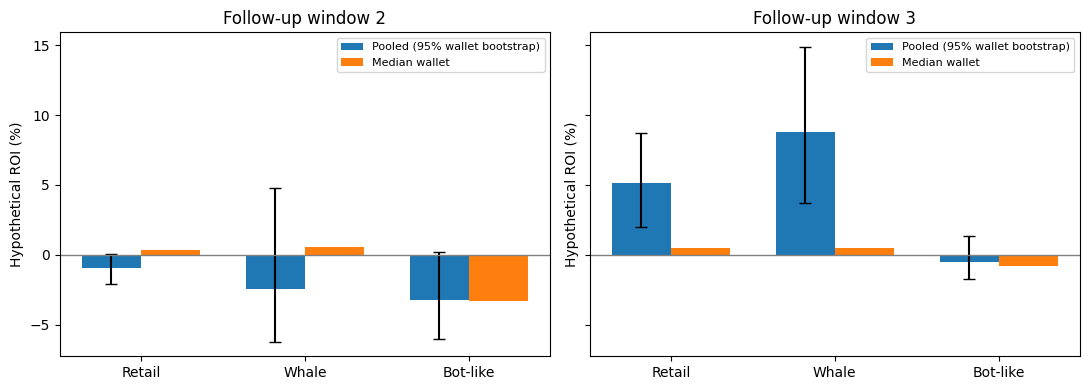

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, window in zip(axes, [2, 3]):
    values = money.loc[window].reindex(group_order).dropna(how="all")
    x = np.arange(len(values))
    errors = [values["pooled_roi_pct"] - values["pooled_roi_low_pct"],
              values["pooled_roi_high_pct"] - values["pooled_roi_pct"]]
    ax.bar(x - 0.18, values["pooled_roi_pct"], width=0.36, yerr=errors, capsize=4, label="Pooled (95% wallet bootstrap)")
    ax.bar(x + 0.18, values["median_wallet_roi_pct"], width=0.36, label="Median wallet")
    ax.axhline(0, color="grey", linewidth=1)
    ax.set_xticks(x, values.index)
    ax.set_title(f"Follow-up window {window}")
    ax.set_ylabel("Hypothetical ROI (%)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3. Skill beyond price

If market prices are fair, a contract bought at price $p$ wins with probability about $p$. For each wallet we compare actual wins with the wins its entry prices imply:

$$z = \frac{\text{wins} - \sum p_i}{\sqrt{\sum p_i(1-p_i)}}$$

over its scored entries (one per wallet × market × outcome × window, as above). $z \approx 0$ means the wallet wins about as often as its prices imply; a large positive $z$ means it wins more than the market expected. Under pure chance, about **2.3%** of wallets would reach $z \ge 2$, so the useful question is whether a group has **more** such wallets than chance, not whether any exist.

Wallets need at least 5 scored entries. Both follow-up windows are pooled per wallet.

In [100]:
from scipy.stats import norm, binomtest

entries = entry_results.assign(p=entry_results["avg_entry_price"].clip(0.001, 0.999))
entries["variance"] = entries["p"] * (1 - entries["p"])
skill = entries.groupby("wallet").agg(
    entries=("won", "size"), wins=("won", "sum"), expected=("p", "sum"), variance=("variance", "sum"),
)
skill = skill[skill["entries"].ge(5)].copy()
skill["z"] = (skill["wins"] - skill["expected"]) / np.sqrt(skill["variance"])
skill["group"] = skill.index.map(group_of)
skill["style"] = skill.index.map(groups.set_index("wallet")["style"]).map(style_names)

chance = norm.sf(2)

def beyond_price(frame):
    hits = int(frame["z"].ge(2).sum())
    return pd.Series({
        "wallets": len(frame), "mean_z": frame["z"].mean(),
        "wins_minus_expected_per_entry_pct": 100 * (frame["wins"].sum() - frame["expected"].sum()) / frame["entries"].sum(),
        "z_ge_2_pct": 100 * hits / len(frame), "chance_pct": 100 * chance,
        "p_value_vs_chance": binomtest(hits, len(frame), chance, alternative="greater").pvalue,
    })

skill_by_group = skill.groupby("group")[["entries", "wins", "expected", "z"]].apply(beyond_price).reindex(group_order).dropna(how="all")
skill_by_style = skill.groupby("style")[["entries", "wins", "expected", "z"]].apply(beyond_price)
display(skill_by_group.round(3))
skill_by_style.round(3)

,wallets,mean_z,wins_minus_expected_per_entry_pct,z_ge_2_pct,chance_pct,p_value_vs_chance
group,,,,,,
Retail,10083.0,-0.047,0.003,1.299,2.275,1.000
Whale,151.0,0.313,1.439,1.987,2.275,0.670
Bot-like,45.0,-0.295,-0.225,4.444,2.275,0.273


,wallets,mean_z,wins_minus_expected_per_entry_pct,z_ge_2_pct,chance_pct,p_value_vs_chance
style,,,,,,
Large near-certainty traders,1884.0,0.021,-0.208,0.212,2.275,1.000
Mid-size mixed-price traders,3043.0,0.001,0.166,1.249,2.275,1.000
Rapid small-ticket traders,568.0,0.124,0.297,2.641,2.275,0.316
Round-the-clock diversified traders,2779.0,-0.234,-1.240,0.252,2.275,1.000
Small long-shot buyers,2005.0,0.051,0.674,3.591,2.275,0.000


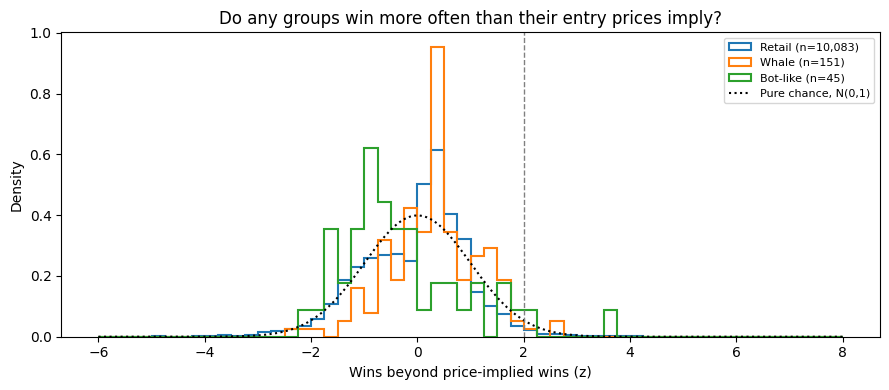

In [101]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(-6, 8, 57)
for group in group_order:
    values = skill.loc[skill["group"].eq(group), "z"].clip(-6, 8)
    if len(values) >= 20:
        ax.hist(values, bins=bins, density=True, histtype="step", linewidth=1.5, label=f"{group} (n={len(values):,})")
grid = np.linspace(-6, 8, 300)
ax.plot(grid, norm.pdf(grid), color="black", linestyle=":", label="Pure chance, N(0,1)")
ax.axvline(2, color="grey", linestyle="--", linewidth=1)
ax.set(xlabel="Wins beyond price-implied wins (z)", ylabel="Density",
       title="Do any groups win more often than their entry prices imply?")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 4. Candidate wallets for a closer look

Non-bot wallets with $z \ge 3$ (about 0.1% expected by chance) and at least 10 scored entries. Wallet IDs are pseudonymous and shortened; this list is a starting point for checking timing against news, **not** an accusation of insider trading.

In [102]:
candidates = skill[skill["z"].ge(3) & skill["entries"].ge(10) & skill["group"].ne("Bot-like")].copy()
candidates["hit_rate_pct"] = 100 * candidates["wins"] / candidates["entries"]
candidates["implied_hit_rate_pct"] = 100 * candidates["expected"] / candidates["entries"]
candidates.index = candidates.index.str.slice(0, 10) + "…"
print(f"Candidates: {len(candidates):,} of {len(skill):,} scored wallets "
      f"(chance alone would give about {norm.sf(3) * len(skill):.1f} at z ≥ 3)")
candidates.sort_values("z", ascending=False)[
    ["group", "style", "entries", "hit_rate_pct", "implied_hit_rate_pct", "z"]
].head(15).round(2)

Candidates: 14 of 10,279 scored wallets (chance alone would give about 13.9 at z ≥ 3)


,group,style,entries,hit_rate_pct,implied_hit_rate_pct,z
wallet,,,,,,
0x41e109dc…,Retail,Small long-shot buyers,17,64.71,26.47,4.3
0x8deb8602…,Retail,Rapid small-ticket traders,254,58.66,47.53,4.15
0x8de3274c…,Retail,Rapid small-ticket traders,209,63.16,53.09,3.97
0xb77076ed…,Retail,Mid-size mixed-price traders,36,66.67,40.75,3.92
0x0b1eed01…,Retail,Mid-size mixed-price traders,12,50.00,23.18,3.59
0x283e095a…,Retail,Small long-shot buyers,158,44.94,34.2,3.53
0x752c1c0e…,Retail,Mid-size mixed-price traders,38,50.00,26.92,3.5
0x7acccc78…,Retail,Small long-shot buyers,165,58.18,48.9,3.47
0x1741c08f…,Retail,Small long-shot buyers,25,20.00,5.06,3.47


### 5. What this adds

* **Groups vs styles:** the crosstab shows which learned styles the simple bot / whale / retail rules fall into.
* **Who makes money:** the bootstrap intervals show whether any group's pooled return is clearly above zero; when an interval crosses zero, the point estimate should not be presented as a profitable group.
* **Skill beyond price:** comparing the share of wallets with $z \ge 2$ with the 2.3% chance level separates "wins often because it buys favorites" from "wins more than prices imply".
* **Limits:** hold-to-resolution ROI ignores sells and fees; entry prices are averaged per entry; groups and styles come from window 1 only; candidate wallets need event-level timing checks before any interpretation.

## Findings

- **Timing features improve the profiles.** Adding when and how simultaneously wallets trade raised separation (silhouette 0.087 → 0.100) and cross-window agreement (ARI 0.364 → 0.437). Settlement-timing features were not stable wallet traits and were left out.
- **A rapid small-ticket style captures the bot-like wallets.** All 83 rule-based bot-like wallets fall into this style, the only one that trades in several markets within the same second. These wallets lost money in both follow-ups (pooled hypothetical ROI −3.2% and −0.5%).
- **Winning often is not the same as earning a high return.** Large near-certainty traders hit 94.9% and 92.7% in the follow-ups, matching their entry prices; their pooled hypothetical ROI is −0.04% and +0.64%.
- **The typical wallet can differ from the pooled result.** Small long-shot buyers return +10.7% pooled in window 3, but the median wallet returns −0.5%.
- **Whales did best only in the last window.** Their pooled ROI is +8.8% (95% wallet bootstrap 3.7% to 14.9%) in window 3, but −2.4% with an interval crossing zero in window 2.
- **No excess of "too good to be chance" wallets.** 14 non-bot wallets have z ≥ 3, against about 13.9 expected by chance, so the data do not show an insider-like excess.
- Economic ordering changes across time, and the outcome sample covers only recorded, qualifying Yes/No purchases with available labels. Missing outcomes are not losses, and the comparisons are observational rather than causal.

The supported interpretation is a descriptive study of trading styles, changes over time, and entry-price/settlement outcomes. It does not establish insider detection, actual wallet PnL, or a consistently superior trading group.